In [3]:
import pandas as pd
import matplotlib.pyplot as mp
import seaborn as sb
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn import decomposition
import os
import re
import unicodedata

os.chdir("F:/DATA SCIENCE/DATA SCIENCE/APRENDIZAJE DE MÁQUINA NO SUPERVISADO/EL ALGORITMO K-MEANS/PROYECTO")

df1 = pd.read_csv("DIM_PRODUCT.csv")
df2 = pd.read_csv("DIM_SEGMENT.csv")
df3 = pd.read_csv("DIM_CATEGORY.csv")
df4 = pd.read_csv("DIM_CALENDAR.csv")
df5 = pd.read_csv("FACT_SALES.csv", dtype={"ITEM_CODE": str})

In [4]:
from IPython.display import display

print("DF1 - PRODUCTOS")
display(df1)

print("DF2 - SEGMENTOS")
display(df2)

print("DF3 - CATEGORÍAS")
display(df3)

print("DF4 - CALENDARIO")
display(df4)

print("DF5 - VENTAS")
display(df5)

DF1 - PRODUCTOS


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
...,...,...,...,...,...,...,...,...,...
500,RECKITT,VANISH,7501058789778BP1,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA
501,INDS. ALEN,CLORALEX,7501025412142,CLORALEX AROMAS BLANQUEADOR C/AROMA LAVANDA GA...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
502,INDS. ALEN,CLORALEX,NaN,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,NaN,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


DF2 - SEGMENTOS


,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH
1,1,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH
2,1,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH
3,1,CLORO,CLORO,MULTIUSOS,GEL,BLEACH
4,1,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH
5,1,CLORO,CLORO,NO DEFINIDO,LIQUIDO,BLEACH
6,1,CLORO,CLORO,NO DEFINIDO,POLVO,BLEACH
7,1,CLORO,CLORO,OTR. TIPOS,LIQUIDO,BLEACH
8,1,CLORO,CLORO,OTR. TIPOS,POLVO,BLEACH
9,1,CLORO,CLORO,ROPA BEBE,LIQUIDO,BLEACH


DF3 - CATEGORÍAS


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


DF4 - CALENDARIO


,WEEK,YEAR,MONTH,WEEK_NUMBER,DATE
0,01-21,2021,1,1,10/01/2021
1,02-21,2021,1,2,17/01/2021
2,03-21,2021,1,3,24/01/2021
3,04-21,2021,1,4,31/01/2021
4,05-21,2021,2,5,07/02/2021
...,...,...,...,...,...
151,48-23,2023,12,48,04/12/2023
152,49-23,2023,12,49,11/12/2023
153,50-23,2023,12,50,18/12/2023
154,51-23,2023,12,51,25/12/2023


DF5 - VENTAS


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,7.50106E+12,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,7.70263E+12,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,7.50106E+12,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,7.50106E+12,2.037,182.839,5.375,TOTAL AUTOS AREA 5
...,...,...,...,...,...,...
121997,26-23,7501058792778BP1,1.192,150.829,4.000,TOTAL AUTOS SCANNING MEXICO
121998,26-23,7.50106E+12,1.947,235.416,2.797,TOTAL AUTOS SCANNING MEXICO
121999,26-23,7.50106E+12,18.013,429.289,9.102,TOTAL AUTOS SCANNING MEXICO
122000,26-23,7702626204208BP1,21.152,210.276,22.172,TOTAL AUTOS SCANNING MEXICO


In [5]:
# LIMPIEZA DE DATOS
# Renombrar columnas

df1.rename(columns={
    'MANUFACTURER':'FABRICANTE','BRAND':'MARCA','ITEM':'CLAVE',
    'ITEM_DESCRIPTION':'DESCRIPCION','CATEGORY':'CATEGORIA',
    'FORMAT':'FORMATO','ATTR1':'PRODUCTO','ATTR2':'FUNCION','ATTR3':'DETALLES'
}, inplace=True)

df2.rename(columns={
    'CATEGORY':'CATEGORIA','ATTR1':'PRODUCTO','ATTR2':'FUNCION',
    'ATTR3':'DETALLES','FORMAT':'FORMATO','SEGMENT':'SEGMENTO'
}, inplace=True)

df3.rename(columns={'ID_CATEGORY':'CATEGORIA','CATEGORY':'DESTINO'}, inplace=True)

df4.rename(columns={
    'WEEK':'SEMANA','YEAR':'ANIO','MONTH':'MES',
    'WEEK_NUMBER':'NUMERO_SEMANA','DATE':'FECHA'
}, inplace=True)

df5.rename(columns={
    'ITEM_CODE':'CLAVE','WEEK':'SEMANA',
    'TOTAL_UNIT_SALES':'TOTAL_UNITARIO_DE_VENTAS',
    'TOTAL_VALUE_SALES':'VALOR_TOTAL_DE_VENTAS',
    'TOTAL_UNIT_AVG_WEEKLY_SALES':'PROMEDIO_TOTAL_UNITARIO_VENTAS_SEMANALES'
}, inplace=True)

In [6]:
# IDENTIFICACIÓN DE VALORES NULOS

In [7]:
df1.isnull().sum()

FABRICANTE     0
MARCA          0
CLAVE          2
DESCRIPCION    0
CATEGORIA      0
FORMATO        0
PRODUCTO       6
FUNCION        0
DETALLES       6
dtype: int64

In [8]:
df2.isnull().sum()

CATEGORIA    0
PRODUCTO     0
FUNCION      0
DETALLES     1
FORMATO      0
SEGMENTO     0
dtype: int64

In [9]:
df3.isnull().sum()

CATEGORIA    0
DESTINO      0
dtype: int64

In [10]:
df4.isnull().sum()

SEMANA           0
ANIO             0
MES              0
NUMERO_SEMANA    0
FECHA            0
dtype: int64

In [11]:
df5.isnull().sum()

SEMANA                                      0
CLAVE                                       0
TOTAL_UNITARIO_DE_VENTAS                    0
VALOR_TOTAL_DE_VENTAS                       0
PROMEDIO_TOTAL_UNITARIO_VENTAS_SEMANALES    0
REGION                                      0
dtype: int64

In [12]:
# Manejo de los valores nulos

df1['CLAVE'] = df1['CLAVE'].fillna("0")
df1['PRODUCTO'] = df1['PRODUCTO'].fillna("NO DEFINIDO")
df1['DETALLES'] = df1['DETALLES'].fillna("NO DEFINIDO")

df2['FUNCION'] = df2['FUNCION'].fillna("NO DEFINIDO")
df2['DETALLES'] = df2['DETALLES'].fillna("NO DEFINIDO")

In [13]:
# Limpieza de texto

df3['DESTINO'] = df3['DESTINO'].str.replace('\r\n','')
df4['SEMANA'] = df4['SEMANA'].str.replace('-', '/')
df5['SEMANA'] = df5['SEMANA'].str.replace('-', '/')

df2.replace({
    "ROSA": "LIMPIAR ROPA COLOR ROSA",
    "ROPA BLANCA": "LIMPIAR ROPA COLOR BLANCO",
    "ROPA COLOR": "LIMPIAR ROPA DE COLOR",
    "BAMBINO": "NIÑO",
    "OTR. TIPOS": "OTROS TIPOS"
}, inplace=True)

In [14]:
# Identificar duplicados

df1.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
500    False
501    False
502    False
503    False
504    False
Length: 505, dtype: bool

In [15]:
df2.duplicated()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10     True
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35    False
36    False
37    False
38    False
39    False
40    False
41    False
42    False
43    False
44    False
45    False
46    False
47    False
48    False
49    False
50    False
51    False
52    False
dtype: bool

In [16]:
df3.duplicated()

0    False
1    False
2    False
3    False
4    False
dtype: bool

In [17]:
df4.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
151    False
152    False
153    False
154    False
155    False
Length: 156, dtype: bool

In [18]:
df5.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
121997    False
121998    False
121999    False
122000    False
122001    False
Length: 122002, dtype: bool

In [19]:
# Eliminar duplicados

df2.drop_duplicates(inplace=True)

In [20]:
# Unión de los dataframes

dfcombinados1 = df1.merge(df2, on=['PRODUCTO','CATEGORIA','FORMATO','FUNCION','DETALLES'], how='left')
dfcombinados2 = dfcombinados1.merge(df3, on='CATEGORIA', how='left')
dfcombinados3 = dfcombinados2.merge(df5, on='CLAVE', how='inner')

In [21]:
# Creación de nueva columna de ventas diarias

dfcombinados3["VENTAS_DIARIAS"] = dfcombinados3['TOTAL_UNITARIO_DE_VENTAS'] / 7

In [22]:
# Limpieza de nombres de columnas (caracteres invisibles y espacios)
dfcombinados3.columns = [re.sub(r'[^\x20-\x7E]', '', col).strip() for col in dfcombinados3.columns]
dfcombinados3.columns = [col.replace(" ", "_").upper() for col in dfcombinados3.columns]

for col in dfcombinados3.select_dtypes(include="object").columns:
    dfcombinados3[col] = dfcombinados3[col].astype(str).str.strip().str.upper()

print("Columnas estandarizadas:", dfcombinados3.columns.tolist())
dfcombinados3.head()

Columnas estandarizadas: ['FABRICANTE', 'MARCA', 'CLAVE', 'DESCRIPCION', 'CATEGORIA', 'FORMATO', 'PRODUCTO', 'FUNCION', 'DETALLES', 'SEGMENTO', 'DESTINO', 'SEMANA', 'TOTAL_UNITARIO_DE_VENTAS', 'VALOR_TOTAL_DE_VENTAS', 'PROMEDIO_TOTAL_UNITARIO_VENTAS_SEMANALES', 'REGION', 'VENTAS_DIARIAS']


,FABRICANTE,MARCA,CLAVE,DESCRIPCION,CATEGORIA,FORMATO,PRODUCTO,FUNCION,DETALLES,SEGMENTO,DESTINO,SEMANA,TOTAL_UNITARIO_DE_VENTAS,VALOR_TOTAL_DE_VENTAS,PROMEDIO_TOTAL_UNITARIO_VENTAS_SEMANALES,REGION,VENTAS_DIARIAS
0,INDS. ALEN,CLORALEX,7501025405298BP2,CLORALEX MAXGEL BOT 600ML+PINOL PINO MULTIU BO...,1,GEL,CLORO,CLORO,MULTIUSOS,BLEACH,FABRIC TREATMENT AND SANIT,26/22,0.001,0.055,1.0,TOTAL AUTOS AREA 5,0.000143
1,INDS. ALEN,CLORALEX,7501025405298BP2,CLORALEX MAXGEL BOT 600ML+PINOL PINO MULTIU BO...,1,GEL,CLORO,CLORO,MULTIUSOS,BLEACH,FABRIC TREATMENT AND SANIT,36/22,0.001,0.055,1.0,TOTAL AUTOS AREA 6,0.000143
2,INDS. ALEN,CLORALEX,7501025405298BP2,CLORALEX MAXGEL BOT 600ML+PINOL PINO MULTIU BO...,1,GEL,CLORO,CLORO,MULTIUSOS,BLEACH,FABRIC TREATMENT AND SANIT,26/22,0.001,0.055,1.0,TOTAL AUTOS SCANNING MEXICO,0.000143
3,INDS. ALEN,CLORALEX,7501025405298BP2,CLORALEX MAXGEL BOT 600ML+PINOL PINO MULTIU BO...,1,GEL,CLORO,CLORO,MULTIUSOS,BLEACH,FABRIC TREATMENT AND SANIT,36/22,0.001,0.055,1.0,TOTAL AUTOS SCANNING MEXICO,0.000143
4,INDS. ALEN,CLORALEX,7501025441326BP2,CLORALEX ELRENDIDORLIQBP950ML+PINOLELORIGCITRI...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,BLEACH,FABRIC TREATMENT AND SANIT,15/22,0.001,0.004,1.0,TOTAL AUTOS AREA 1,0.000143


In [23]:
# Modificación en el formato de fechas
dfcombinados3 = dfcombinados3.merge(df4, on="SEMANA", how="left")
dfcombinados3['FECHA'] = pd.to_datetime(dfcombinados3['FECHA'], dayfirst=True)

In [24]:
# Modelado de los datos para KMeans (unificar los datos repetidos y dejar los que contienen información irrelevante)
df_kmeans = dfcombinados3.groupby('CLAVE').agg({
    'TOTAL_UNITARIO_DE_VENTAS': 'sum',
    'VALOR_TOTAL_DE_VENTAS': 'sum',
    'VENTAS_DIARIAS': 'mean',
    'PROMEDIO_TOTAL_UNITARIO_VENTAS_SEMANALES': 'mean'
}).reset_index()

# Nueva variable "Precio promedio"

df_kmeans['PRECIO_PROMEDIO'] = df_kmeans['VALOR_TOTAL_DE_VENTAS'] / df_kmeans['TOTAL_UNITARIO_DE_VENTAS']
df_kmeans['PRECIO_PROMEDIO'] = df_kmeans['PRECIO_PROMEDIO'].replace([float('inf'), -float('inf')], 0)
df_kmeans['PRECIO_PROMEDIO'] = df_kmeans['PRECIO_PROMEDIO'].fillna(0)

X = df_kmeans.drop('CLAVE', axis=1)

In [25]:
# Estandarización de las características
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [26]:
print(X_scaled.columns.tolist())

['TOTAL_UNITARIO_DE_VENTAS', 'VALOR_TOTAL_DE_VENTAS', 'VENTAS_DIARIAS', 'PROMEDIO_TOTAL_UNITARIO_VENTAS_SEMANALES', 'PRECIO_PROMEDIO']


In [27]:
# Aplicación de algoritmo de KMeans

fields = X_scaled.values

import warnings
warnings.filterwarnings("ignore")

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=2)
    kmeans.fit(fields)
    wcss.append(kmeans.inertia_)

Text(0, 0.5, 'WCSS')

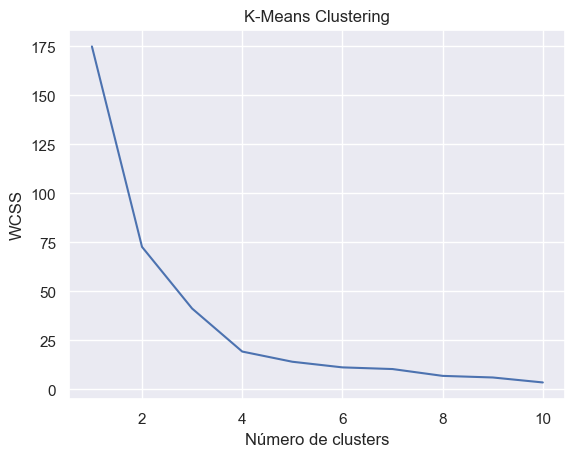

In [28]:
# Graficación del "Codo de Jambu"
sb.set()
mp.plot(range(1,11), wcss)
mp.title("K-Means Clustering")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS") #Weighted cluster sum of squares

In [29]:
kmeans_2d = KMeans(n_clusters = 3, init = "k-means++", random_state=42)
cluster_values_2d = kmeans_2d.fit_predict(fields)
print(cluster_values_2d)

[0 0 0 0 0 0 0 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


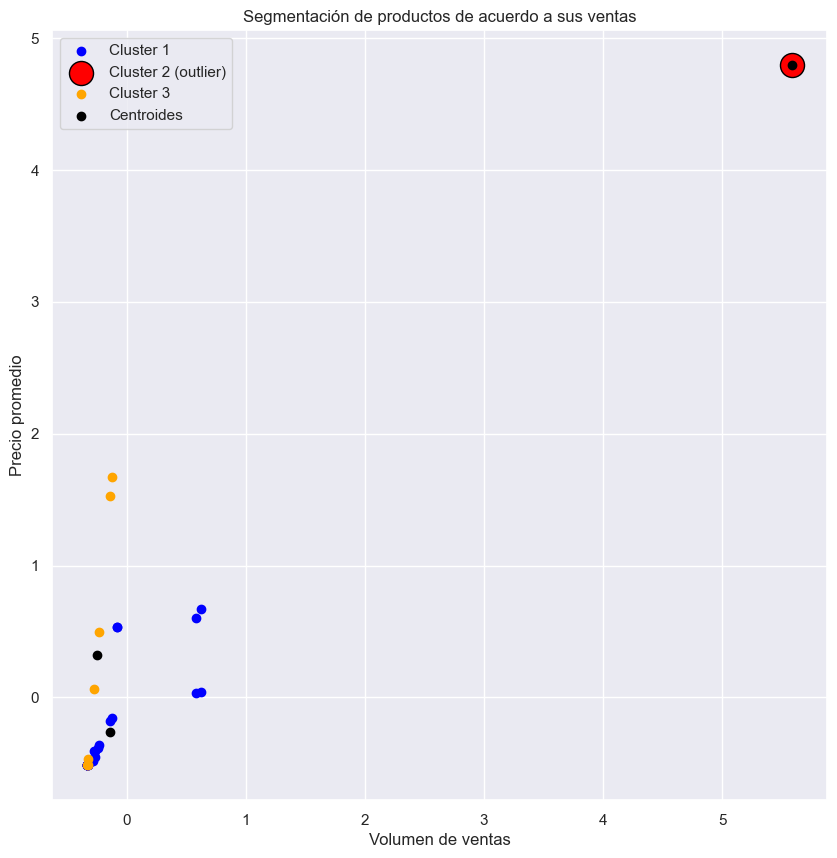

In [30]:
mp.figure(figsize =(10,10))
mp.scatter(fields[cluster_values_2d==0,0], fields[cluster_values_2d==0,1], c ='blue', label = 'Cluster 1')
mp.scatter(fields[cluster_values_2d==1,0], fields[cluster_values_2d==1,1], c ='red', s=300, edgecolors='black', label='Cluster 2 (outlier)')
mp.scatter(fields[cluster_values_2d==2,0], fields[cluster_values_2d==2,1], c ='orange', label = 'Cluster 3')

mp.scatter(kmeans_2d.cluster_centers_[:,0], kmeans_2d.cluster_centers_[:,1],
          c='black', label='Centroides')

mp.title("Segmentación de productos de acuerdo a sus ventas")
mp.xlabel("Volumen de ventas")
mp.ylabel("Precio promedio")

mp.legend()
mp.show()

In [31]:
import numpy as np
print(np.bincount(cluster_values_2d))

[27  1  7]


In [32]:
# Criterio de Silueta ("Silhouette")
from sklearn import datasets
from sklearn.metrics import silhouette_score

In [33]:
for j in range(2,11):
    kmeans = KMeans(n_clusters=j, random_state=42)
    labels = kmeans.fit_predict(fields)
    score = silhouette_score(fields, labels)
    print(f"k = {j}, silhouette = {score}")

k = 2, silhouette = 0.7966513617134183
k = 3, silhouette = 0.467810482686656
k = 4, silhouette = 0.5306746946813409
k = 5, silhouette = 0.3998125892624641
k = 6, silhouette = 0.32902836651022044
k = 7, silhouette = 0.3227531898756412
k = 8, silhouette = 0.41190398344701395
k = 9, silhouette = 0.46510072052827667
k = 10, silhouette = 0.4715882255817998


In [34]:
kmeans_2d_2 = KMeans(n_clusters = 2, init = "k-means++", random_state=42)
cluster_values_2d_2 = kmeans_2d_2.fit_predict(fields)
print(cluster_values_2d_2)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


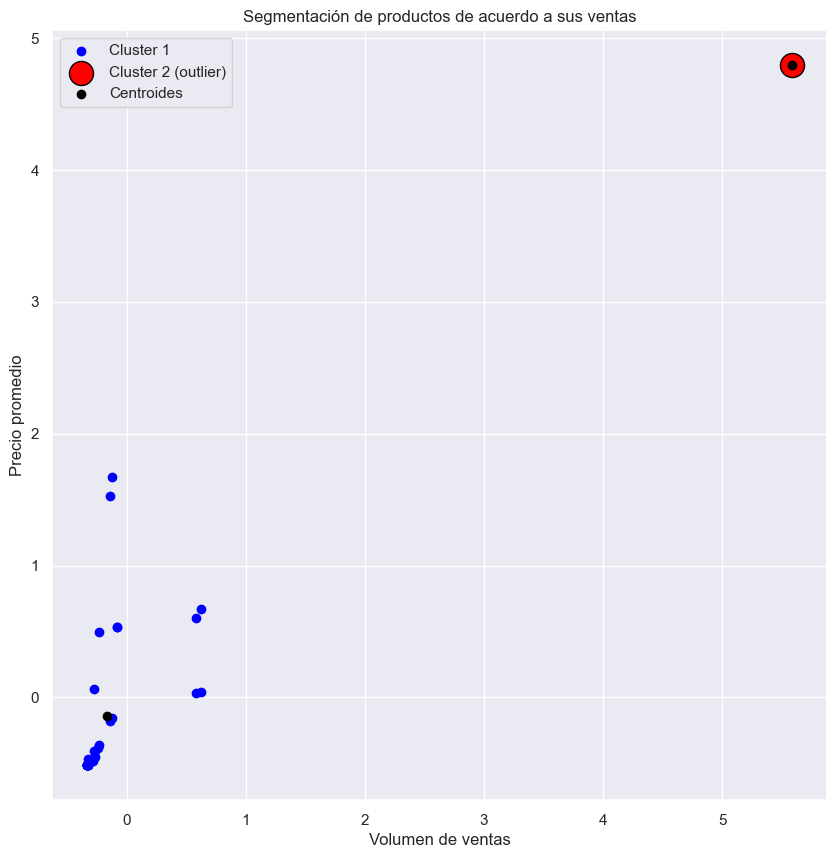

In [35]:
mp.figure(figsize =(10,10))
mp.scatter(fields[cluster_values_2d_2==0,0], fields[cluster_values_2d_2==0,1], c='blue', label='Cluster 1')

mp.scatter(fields[cluster_values_2d_2==1,0], fields[cluster_values_2d_2==1,1], c='red', s=300, edgecolors='black', label='Cluster 2 (outlier)')

mp.scatter(kmeans_2d_2.cluster_centers_[:,0], kmeans_2d_2.cluster_centers_[:,1],
          c='black', label='Centroides')

mp.title("Segmentación de productos de acuerdo a sus ventas")
mp.xlabel("Volumen de ventas")
mp.ylabel("Precio promedio")

mp.legend()
mp.show()

In [36]:
# Algoritmo KMeans aplicado a cinco columnas de nuestra base original
# bajo una transformación de PCA.

fields2 = X_scaled.iloc[:, [0,1,2,3,4]].values
print(fields2)

[[-0.32943586 -0.51506418 -0.35523587 -0.85194516  0.25153861]
 [-0.32944156 -0.51511421 -0.35523587 -0.85194516 -0.96947688]
 [-0.32941308 -0.51508306 -0.35491603 -0.85194516 -0.78592553]
 [-0.32941308 -0.51507739 -0.35491603 -0.85194516 -0.73804257]
 [-0.26910481 -0.45360497 -0.20888492  0.66886044 -0.77071491]
 [-0.26910481 -0.4103815  -0.20888492  0.66886044 -0.56375208]
 [-0.32940738 -0.5150755  -0.35123788 -0.01989125 -0.77110462]
 [-0.32900293 -0.51371043 -0.35341761 -0.62550796 -0.15116937]
 [-0.32944156 -0.51507362 -0.35523587 -0.85194516  1.08949041]
 [-0.32927636 -0.51406586 -0.35314461 -0.65993272  0.71041698]
 [-0.1373033   1.52862371 -0.14362674 -0.37321028  2.00798355]
 [-0.1373033  -0.18241178 -0.14362674 -0.37321028 -0.56494639]
 [-0.12164662  1.6744558  -0.13115963 -0.25651129  1.97920134]
 [-0.12164662 -0.15867419 -0.13115963 -0.25651129 -0.56963566]
 [-0.2346584   0.49238296 -0.20433859 -0.13212459  2.00578006]
 [-0.2346584  -0.3645709  -0.20433859 -0.13212459 -0.60

In [37]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca.fit(fields2)
fields2 = pca.transform(fields2)
fields2

array([[-1.02846035,  0.18967512],
       [-0.87301542, -0.91588261],
       [-0.89618998, -0.74966728],
       [-0.90228424, -0.70631072],
       [-0.0535365 , -1.0209261 ],
       [-0.05957319, -0.81768805],
       [-0.5089112 , -0.90843139],
       [-0.86998686, -0.22126473],
       [-1.13516383,  0.94837475],
       [-0.99588018,  0.56583397],
       [ 0.14228749,  2.44531798],
       [-0.33431991, -0.51165654],
       [ 0.28350236,  2.44963563],
       [-0.25355941, -0.53029228],
       [-0.31485905,  2.0073253 ],
       [-0.38504055, -0.67198583],
       [-0.66879956,  1.79059579],
       [-0.58592894, -0.54559025],
       [-0.85799747,  1.26654176],
       [-0.59180877, -0.77948614],
       [-1.21630462,  1.95599918],
       [-0.86140821, -0.58320364],
       [ 0.01172247,  0.37793986],
       [ 0.01172247,  0.37793986],
       [-0.72017474, -0.26480313],
       [-0.39749645, -0.68691398],
       [-0.97764862, -0.17161108],
       [-0.82096598, -0.27814971],
       [ 1.75418582,

In [38]:
wcss2 = []
for index in range(1,11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields2)
    wcss2.append (kmeans.inertia_)

Text(0, 0.5, 'WCSS')

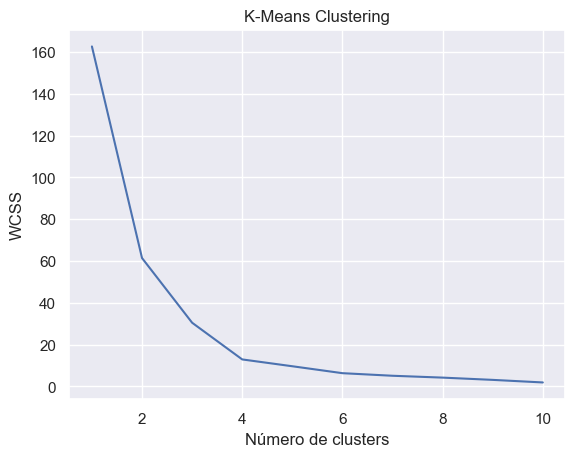

In [39]:
# Graficación del "Codo de Jambu"
sb.set()
mp.plot(range(1,11), wcss2)
mp.title("K-Means Clustering")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS") #Weighted cluster sum of squares

In [40]:
kmeans_pca = KMeans(n_clusters = 3, init = "k-means++", random_state=42)
cluster_values_pca = kmeans_pca.fit_predict(fields2)
print(cluster_values_pca)

[0 0 0 0 0 0 0 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


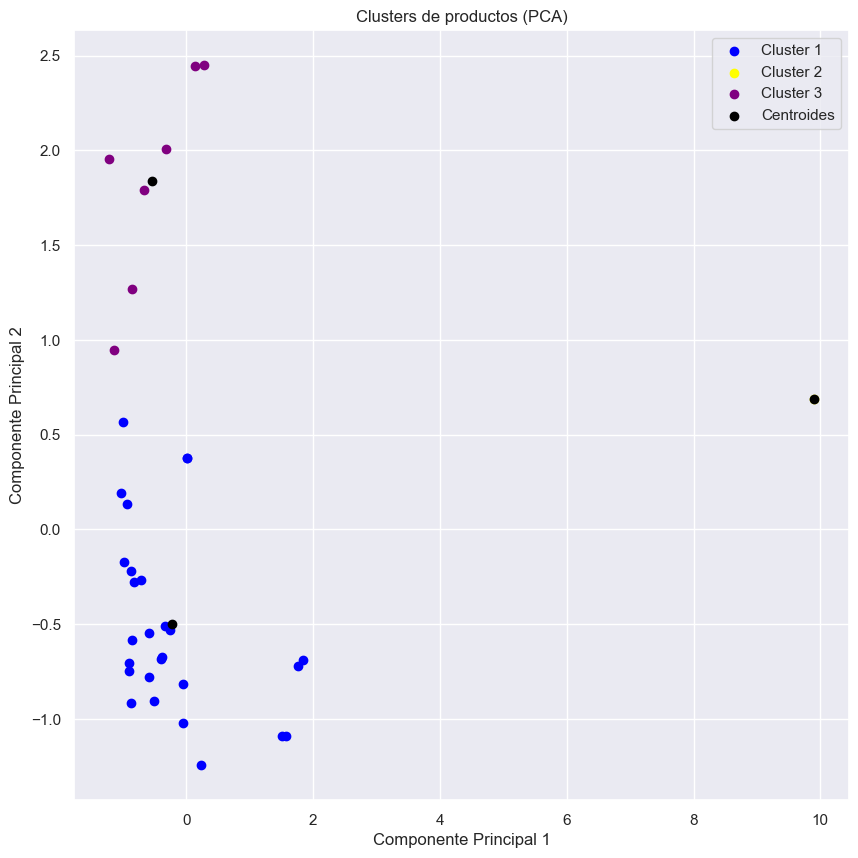

In [41]:
mp.figure(figsize =(10,10))
mp.scatter(fields2[cluster_values_pca==0,0], fields2[cluster_values_pca==0,1], c ='blue', label = 'Cluster 1')
mp.scatter(fields2[cluster_values_pca==1,0], fields2[cluster_values_pca==1,1], c ='yellow', label = 'Cluster 2')
mp.scatter(fields2[cluster_values_pca==2,0], fields2[cluster_values_pca==2,1], c ='purple', label = 'Cluster 3')

mp.scatter(kmeans_pca.cluster_centers_[:,0], kmeans_pca.cluster_centers_[:,1],
          c='black', label='Centroides')

mp.title("Clusters de productos (PCA)")
mp.xlabel("Componente Principal 1")
mp.ylabel("Componente Principal 2")

mp.legend()
mp.show()

In [42]:
# Nueva asignación de variables que se identificaron
mapa_categoria = {
    'CLORO': 1,
    'PRELAVADOR': 2,
    'SAFE BLEACH': 3,
    'SANITIZANTE': 4
}

dfcombinados3['CATEGORIA_ANALITICA'] = dfcombinados3['PRODUCTO'].map(mapa_categoria)

dfcombinados3['CATEGORIA_NOMBRE'] = dfcombinados3['CATEGORIA_ANALITICA'].map({
    1: 'CLORO',
    2: 'PRELAVADOR',
    3: 'SAFE BLEACH',
    4: 'SANITIZANTE'
})

In [43]:
# ASIGNAR CLUSTER A CADA PRODUCTO
# AGRUPAR POR CATEGORÍA

df_categoria = dfcombinados3.groupby('CATEGORIA_NOMBRE').agg({
    'TOTAL_UNITARIO_DE_VENTAS': 'sum',
    'VALOR_TOTAL_DE_VENTAS': 'sum'
}).reset_index()

df_categoria['PRECIO_PROMEDIO'] = (
    df_categoria['VALOR_TOTAL_DE_VENTAS'] /
    df_categoria['TOTAL_UNITARIO_DE_VENTAS']
)

In [44]:
X_cat = df_categoria[['TOTAL_UNITARIO_DE_VENTAS', 'PRECIO_PROMEDIO']]

scaler_cat = StandardScaler()
X_cat_scaled = scaler_cat.fit_transform(X_cat)

In [45]:
kmeans_cat = KMeans(n_clusters=3, random_state=42)
df_categoria['CLUSTER'] = kmeans_cat.fit_predict(X_cat_scaled)

print(df_categoria)

  CATEGORIA_NOMBRE  TOTAL_UNITARIO_DE_VENTAS  VALOR_TOTAL_DE_VENTAS  \
0            CLORO                  1369.226              15324.001   
1      SAFE BLEACH                  2647.834              60502.078   
2      SANITIZANTE                    31.308                565.219   

   PRECIO_PROMEDIO  CLUSTER  
0        11.191725        2  
1        22.849649        0  
2        18.053501        1  


In [46]:
# AGRUPAR POR REGIÓN

df_region = dfcombinados3.groupby('REGION').agg({
    'TOTAL_UNITARIO_DE_VENTAS': 'sum',
    'VALOR_TOTAL_DE_VENTAS': 'sum'
}).reset_index()

df_region['PRECIO_PROMEDIO'] = (
    df_region['VALOR_TOTAL_DE_VENTAS'] /
    df_region['TOTAL_UNITARIO_DE_VENTAS']
)

X_reg = df_region[['TOTAL_UNITARIO_DE_VENTAS', 'PRECIO_PROMEDIO']]

scaler_reg = StandardScaler()
X_reg_scaled = scaler_reg.fit_transform(X_reg)

kmeans_reg = KMeans(n_clusters=3, random_state=42)
df_region['CLUSTER'] = kmeans_reg.fit_predict(X_reg_scaled)

print(df_region)

                        REGION  TOTAL_UNITARIO_DE_VENTAS  \
0           TOTAL AUTOS AREA 1                   192.071   
1           TOTAL AUTOS AREA 2                   426.165   
2           TOTAL AUTOS AREA 3                   345.088   
3           TOTAL AUTOS AREA 4                   297.422   
4           TOTAL AUTOS AREA 5                   444.083   
5           TOTAL AUTOS AREA 6                   319.358   
6  TOTAL AUTOS SCANNING MEXICO                  2024.181   

   VALOR_TOTAL_DE_VENTAS  PRECIO_PROMEDIO  CLUSTER  
0               3264.049        16.993971        2  
1               7726.485        18.130266        2  
2               6619.190        19.181165        2  
3               4961.836        16.682814        2  
4              10763.789        24.238237        0  
5               4860.340        15.219096        2  
6              38195.609        18.869661        1  


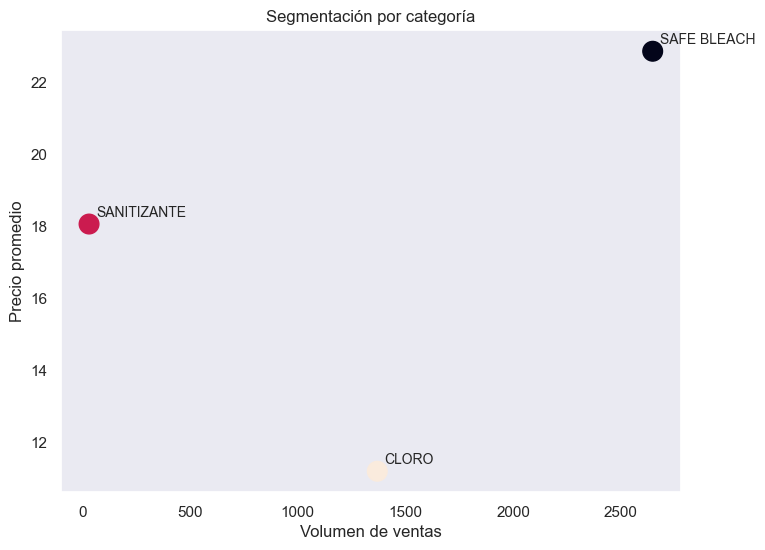

In [47]:
mp.figure(figsize=(8,6))

mp.scatter(df_categoria['TOTAL_UNITARIO_DE_VENTAS'],
           df_categoria['PRECIO_PROMEDIO'],
           c=df_categoria['CLUSTER'],
           s=200)

# Etiquetas (clave para que se entienda)
for i, txt in enumerate(df_categoria['CATEGORIA_NOMBRE']):
    mp.annotate(txt,
                (df_categoria['TOTAL_UNITARIO_DE_VENTAS'][i],
                 df_categoria['PRECIO_PROMEDIO'][i]),
                fontsize=10,
                xytext=(5,5),
                textcoords='offset points')

mp.xlabel("Volumen de ventas")
mp.ylabel("Precio promedio")
mp.title("Segmentación por categoría")
mp.grid()

mp.show()

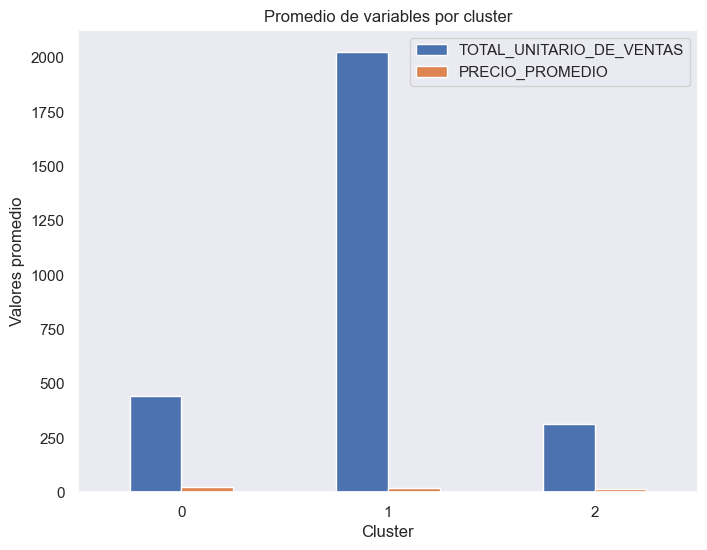

In [48]:
df_cluster = df_region.groupby('CLUSTER').agg({
    'TOTAL_UNITARIO_DE_VENTAS': 'mean',
    'PRECIO_PROMEDIO': 'mean'
}).reset_index()

df_cluster.set_index('CLUSTER').plot(kind='bar', figsize=(8,6))

mp.title("Promedio de variables por cluster")
mp.ylabel("Valores promedio")
mp.xlabel("Cluster")
mp.xticks(rotation=0)
mp.grid()

mp.show()

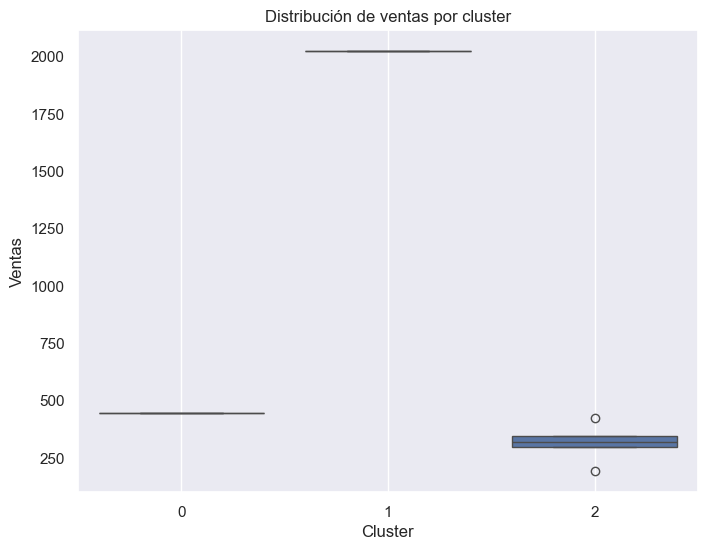

In [49]:
mp.figure(figsize=(8,6))
sb.boxplot(x='CLUSTER', y='TOTAL_UNITARIO_DE_VENTAS', data=df_region)

mp.title("Distribución de ventas por cluster")
mp.xlabel("Cluster")
mp.ylabel("Ventas")
mp.grid()

mp.show()

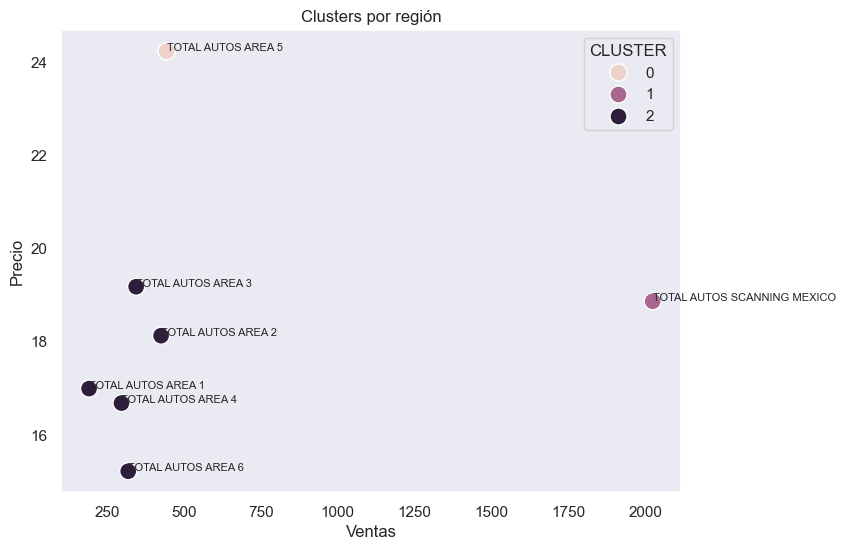

In [50]:
mp.figure(figsize=(8,6))

sb.scatterplot(
    x='TOTAL_UNITARIO_DE_VENTAS',
    y='PRECIO_PROMEDIO',
    hue='CLUSTER',
    data=df_region,
    s=150
)

for i in range(len(df_region)):
    mp.text(df_region['TOTAL_UNITARIO_DE_VENTAS'][i],
            df_region['PRECIO_PROMEDIO'][i],
            df_region['REGION'][i],
            fontsize=8)

mp.title("Clusters por región")
mp.xlabel("Ventas")
mp.ylabel("Precio")
mp.grid()

mp.show()

In [51]:
print("Marcas en df1:", df1['MARCA'].nunique())
print("Marcas en dfcombinados3:", dfcombinados3['MARCA'].nunique())

Marcas en df1: 33
Marcas en dfcombinados3: 6


In [52]:
marcas_df1 = set(df1['MARCA'])
marcas_df3 = set(dfcombinados3['MARCA'])

print("Marcas sin ventas:")
print(marcas_df1 - marcas_df3)

Marcas sin ventas:
{'SHOUT', 'DR.BECKMANN', 'MARIPOSA', 'LA JAPONESA', 'VANISH PODER 02', 'PURO SOL', 'IBERIA', 'CUELLOS PUNOS Y MANCHITAS', 'LA VALENCIANA', 'TIDE', 'HARPIC', 'WHITE MAGIC', 'CLORO 10', 'BLANCATEL', 'LOS PATITOS', 'OXI CLEAN', 'RADIANTE', 'CLARASOL', 'VANISH EXTRA HIGIENE', 'PATITO', 'CLORALUZ', 'OTHERS MARCA UNIF.', 'SANYTOL', 'CARISMA', 'VANISH CRYSTAL WHITE', 'CLORTEX', 'ARTIC WHITE'}


In [53]:
tabla_pivot = pd.pivot_table(
    dfcombinados3,
    values='VALOR_TOTAL_DE_VENTAS',
    index='MARCA',
    columns='CATEGORIA_NOMBRE',
    aggfunc='sum',
    fill_value=0
)

print(tabla_pivot)

CATEGORIA_NOMBRE      CLORO  SAFE BLEACH  SANITIZANTE
MARCA                                                
BANDERA           14466.323        0.000        0.000
BCLORHADA           140.369        0.000        0.000
CLORALEX            704.935        0.000        0.000
CLOROX               12.374        0.000        0.000
LYSOL                 0.000        0.000      565.219
VANISH                0.000    60502.078        0.000


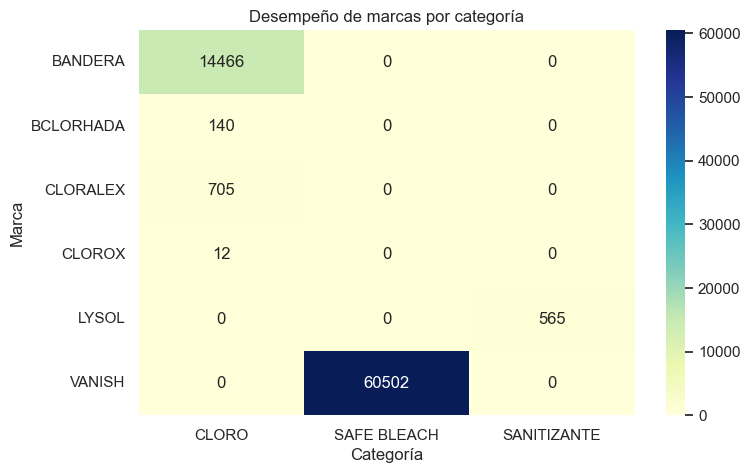

In [54]:
mp.figure(figsize=(8,5))
sb.heatmap(tabla_pivot, annot=True, fmt=".0f", cmap="YlGnBu")

mp.title("Desempeño de marcas por categoría")
mp.xlabel("Categoría")
mp.ylabel("Marca")

mp.show()